# Лаб. 4, клітинні автомати

## 1. Гра «Життя»

Поле з клітин зі станами $0$ (мертва) і $1$ (жива). На кожному кроці всі клітини оновлюються одночасно,
$n$ — кількість живих серед 8 сусідів:

$$s^{t+1} = \begin{cases} 1, & n = 3 \\ s^t, & n = 2 \\ 0, & \text{інакше} \end{cases}$$

Пульсуючі конфігурації повторюються з періодом (мигалка, жаба, маяк — період 2),
рухомі — через кілька кроків повторюють форму, але зсунуті (планер, космічний корабель — через 4 кроки).

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from matplotlib.colors import ListedColormap
from IPython.display import HTML

MOORE = [(-1, -1), (-1, 0), (-1, 1), (0, -1), (0, 1), (1, -1), (1, 0), (1, 1)]
VN = [(-1, 0), (1, 0), (0, -1), (0, 1)]


def neighbors(a, shifts, wrap=True):
    a = a.astype(int)
    if wrap:
        return sum(np.roll(a, s, axis=(0, 1)) for s in shifts)
    p = np.pad(a, 1)
    n, m = a.shape
    return sum(p[1 + di:1 + di + n, 1 + dj:1 + dj + m] for di, dj in shifts)


def animate(frames, cmap, titles, interval=150):
    fig, ax = plt.subplots(figsize=(5, 5))
    im = ax.imshow(frames[0], cmap=cmap, vmin=0, vmax=cmap.N - 1, interpolation="nearest")
    ax.set_xticks([]); ax.set_yticks([])
    title = ax.set_title(titles[0])

    def update(k):
        im.set_data(frames[k])
        title.set_text(titles[k])
        return im, title

    anim = FuncAnimation(fig, update, frames=len(frames), interval=interval)
    plt.close(fig)
    return HTML(anim.to_jshtml())


def show(frames, cmap, titles):
    fig, axes = plt.subplots(1, len(frames), figsize=(2.4 * len(frames), 2.6))
    for ax, f, t in zip(axes, frames, titles):
        ax.imshow(f, cmap=cmap, vmin=0, vmax=cmap.N - 1, interpolation="nearest")
        ax.set_xticks([]); ax.set_yticks([])
        ax.set_title(t, fontsize=10)
    plt.tight_layout()
    plt.show()

In [ ]:
def life_step(g):
    n = neighbors(g, MOORE)
    return ((n == 3) | ((n == 2) & (g == 1))).astype(int)


def life_run(g, steps):
    frames = [g]
    for _ in range(steps):
        frames.append(life_step(frames[-1]))
    return frames


patterns = {
    "мигалка":  ["111"],
    "жаба":     [".111",
                 "111."],
    "маяк":     ["11..",
                 "11..",
                 "..11",
                 "..11"],
    "планер":   [".1.",
                 "..1",
                 "111"],
    "корабель": [".1..1",
                 "1....",
                 "1...1",
                 "1111."],
}


def place(g, name, i, j):
    p = np.array([[c == "1" for c in row] for row in patterns[name]], dtype=int)
    g[i:i + p.shape[0], j:j + p.shape[1]] = p


life_cmap = ListedColormap(["white", "black"])

### Пульсуючі конфігурації

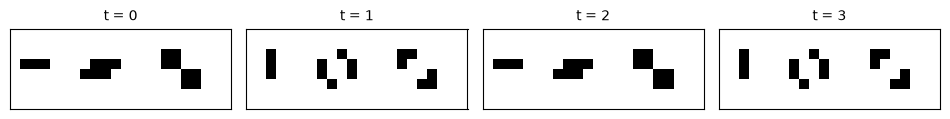

In [ ]:
g = np.zeros((8, 22), dtype=int)
place(g, "мигалка", 3, 1)
place(g, "жаба", 3, 7)
place(g, "маяк", 2, 15)
show(life_run(g, 3), life_cmap, [f"t = {t}" for t in range(4)])

### Рухомі конфігурації

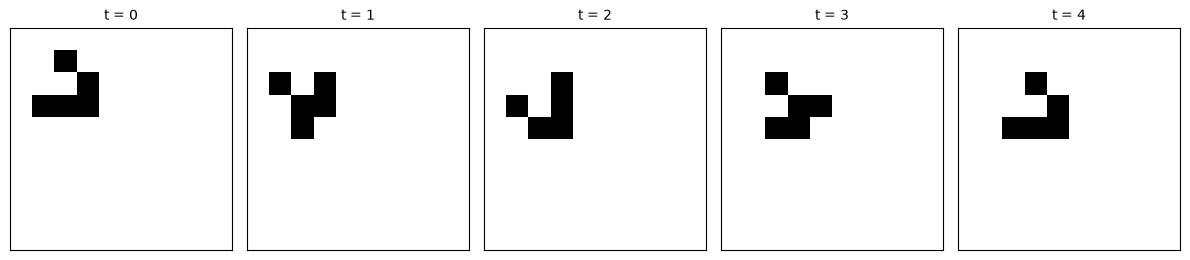

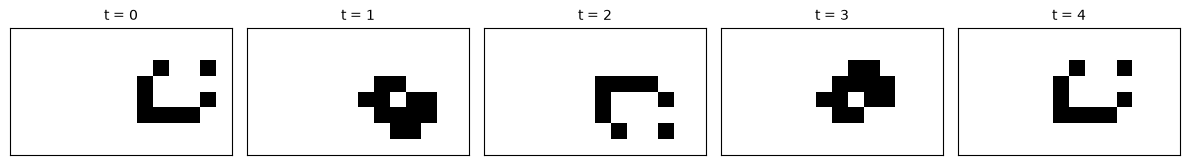

In [ ]:
g = np.zeros((10, 10), dtype=int)
place(g, "планер", 1, 1)
show(life_run(g, 4), life_cmap, [f"t = {t}" for t in range(5)])

g = np.zeros((8, 14), dtype=int)
place(g, "корабель", 2, 8)
show(life_run(g, 4), life_cmap, [f"t = {t}" for t in range(5)])

In [ ]:
g = np.zeros((40, 40), dtype=int)
place(g, "планер", 2, 2)
place(g, "планер", 2, 20)
place(g, "корабель", 25, 2)
place(g, "мигалка", 20, 30)
place(g, "жаба", 32, 25)
place(g, "маяк", 10, 32)

frames = life_run(g, 80)
animate(frames, life_cmap, [f"t = {t}" for t in range(len(frames))], interval=120)

## 2. «Стригучий лишай»

Ділянка шкіри $N \times N$ ($N$ — непарне), інфекція починається з центральної клітини.
Стан клітини — лічильник $s$:
- $s = 0$ — здорова;
- $s = 1, \dots, 6$ — заражена;
- $s = 7, \dots, 10$ — несприйнятлива (імунітет);
- після $s = 10$ клітина знову здорова.

На кожному кроці заражена клітина з імовірністю $p$ заражає кожну здорову сусідню (з 8),
у заражених і несприйнятливих $s \to s + 1$.

In [ ]:
INF, IMM = 6, 4


def lichen_run(N=51, p=0.5, steps=60, seed=0):
    rng = np.random.default_rng(seed)
    s = np.zeros((N, N), dtype=int)
    s[N // 2, N // 2] = 1
    frames = [s.copy()]
    for _ in range(steps):
        k = neighbors((s >= 1) & (s <= INF), MOORE, wrap=False)
        new = (s == 0) & (rng.random(s.shape) < 1 - (1 - p)**k)
        s[s > 0] += 1
        s[s > INF + IMM] = 0
        s[new] = 1
        frames.append(np.where(s == 0, 0, np.where(s <= INF, 1, 2)))
    return frames


# бежевий — здорова, червоний — заражена, синій — несприйнятлива
lichen_cmap = ListedColormap(["#f3d6b5", "#c0392b", "#2c7fb8"])

In [ ]:
frames = lichen_run(p=0.5)
animate(frames, lichen_cmap, [f"p = 0.5, t = {t}" for t in range(len(frames))])

### Різні ймовірності зараження

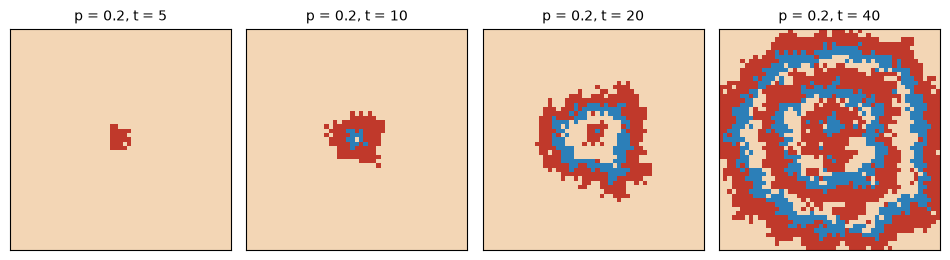

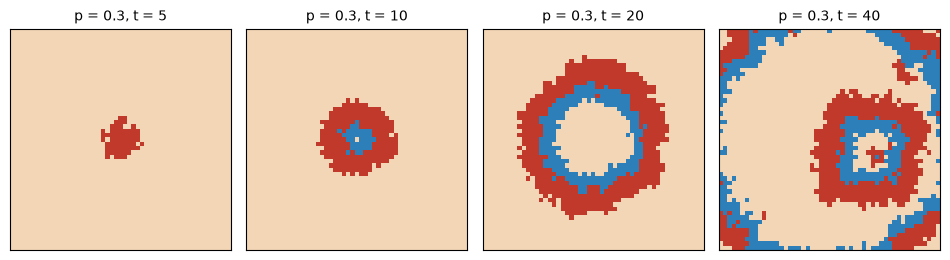

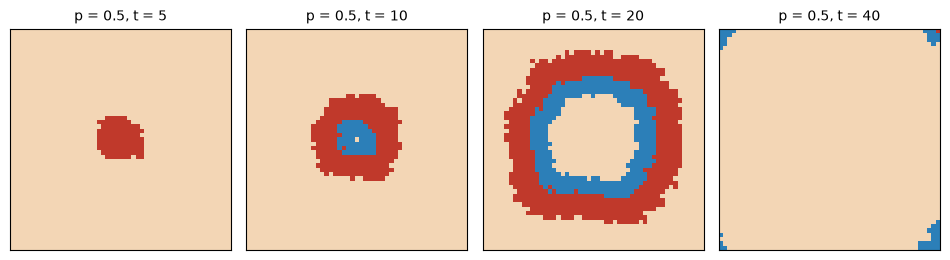

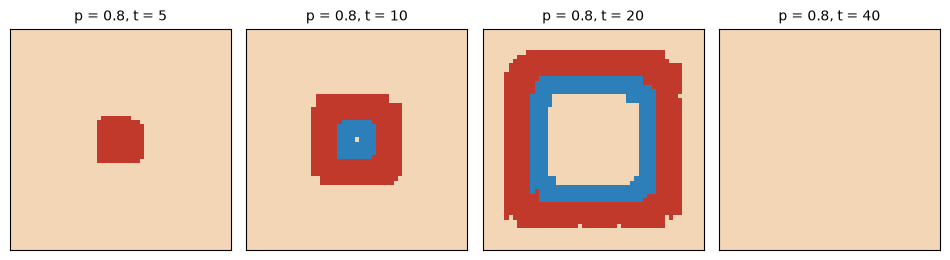

In [ ]:
times = [5, 10, 20, 40]
for p in [0.2, 0.3, 0.5, 0.8]:
    frames = lichen_run(p=p, steps=max(times))
    show([frames[t] for t in times], lichen_cmap, [f"p = {p}, t = {t}" for t in times])

### Підзавдання: ймовірність ураження центральної клітини

Центральна клітина здорова, $k$ з 8 сусідів уражені, кожен заражає її незалежно з імовірністю $p = 1/2$.
Клітина не заразиться, лише якщо її не заразить жоден із $k$ сусідів:

$$P(\text{не заразиться}) = \left(\tfrac{1}{2}\right)^k, \qquad P_k = 1 - \left(\tfrac{1}{2}\right)^k = \frac{2^k - 1}{2^k}$$

$P_0 = 0,\quad P_1 = \tfrac12,\quad P_2 = \tfrac34,\quad P_3 = \tfrac78,\quad P_4 = \tfrac{15}{16},\quad P_5 = \tfrac{31}{32},\quad P_6 = \tfrac{63}{64},\quad P_7 = \tfrac{127}{128},\quad P_8 = \tfrac{255}{256}$

In [1]:
from fractions import Fraction

print(" k |  P_k (дріб) |  P_k")
print("---|-------------|----------")
for k in range(9):
    P = 1 - Fraction(1, 2)**k
    print(f" {k} | {str(P):>11s} | {float(P):.6f}")

 k |  P_k (дріб) |  P_k
---|-------------|----------
 0 |           0 | 0.000000
 1 |         1/2 | 0.500000
 2 |         3/4 | 0.750000
 3 |         7/8 | 0.875000
 4 |       15/16 | 0.937500
 5 |       31/32 | 0.968750
 6 |       63/64 | 0.984375
 7 |     127/128 | 0.992188
 8 |     255/256 | 0.996094


## 3. Розповсюдження лісової пожежі

Стани: $0$ — порожньо, $1$ — горить, $2$ — ліс. Враховуються 4 сусіди.

$$s^{t+1} = \begin{cases}
0, & s^t = 1 \\
1, & s^t = 2 \text{ і хоча б один із 4 сусідів горить} \\
1 \text{ з імовірністю } f, & s^t = 2 \text{ (блискавка)} \\
2 \text{ з імовірністю } g, & s^t = 0 \text{ (ріст лісу)} \\
s^t, & \text{інакше}
\end{cases}$$

$f = 0.000005$, $g = 0.01$. На старті все поле — ліс.

In [ ]:
def fire_run(N=100, f=5e-6, g=0.01, steps=1000, every=1, seed=0):
    rng = np.random.default_rng(seed)
    s = np.full((N, N), 2)
    frames = [s.copy()]
    for t in range(1, steps + 1):
        burning = neighbors(s == 1, VN, wrap=False) > 0
        r = rng.random(s.shape)
        new = s.copy()
        new[s == 1] = 0
        new[(s == 2) & (burning | (r < f))] = 1
        new[(s == 0) & (r < g)] = 2
        s = new
        if t % every == 0:
            frames.append(s.copy())
    return frames


fire_cmap = ListedColormap(["black", "red", "#22dd22"])

In [ ]:
frames = fire_run(f=5e-6, steps=600, every=4)
animate(frames, fire_cmap, [f"f = 5e-6, t = {4 * k}" for k in range(len(frames))], interval=100)

### Різні ймовірності початку горіння

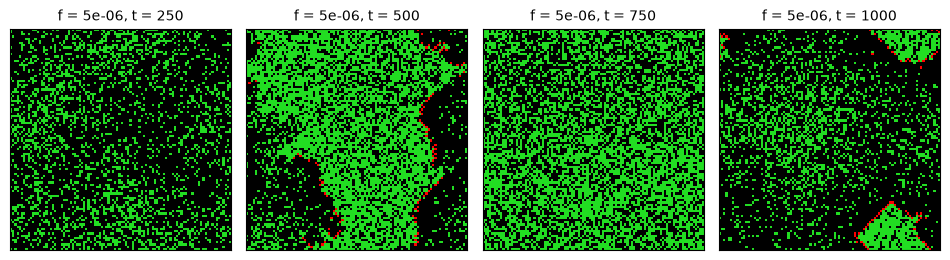

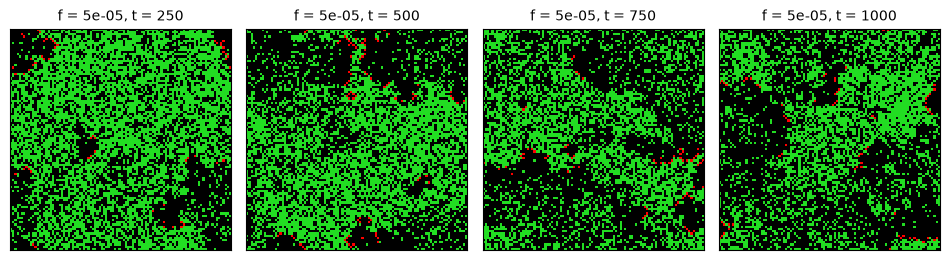

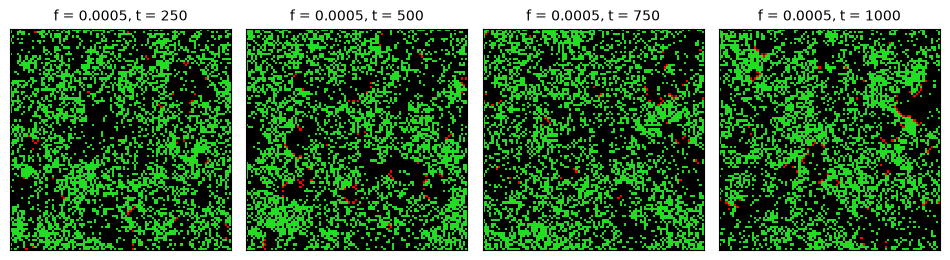

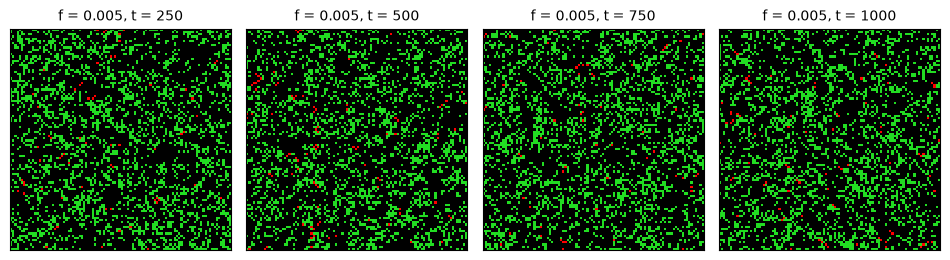

In [ ]:
for f in [5e-6, 5e-5, 5e-4, 5e-3]:
    frames = fire_run(f=f, steps=1000, every=250)
    show(frames[1:], fire_cmap, [f"f = {f}, t = {250 * k}" for k in range(1, 5)])